### **Ejercicio 2**

--> **Importamos librerías que vamos a usar**

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True


--> **Cargamos los datos**

In [18]:
# Carga
auto1 = np.load("c:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Forecasting\\tarea_2\\PHASE_2\\data\\Appendix 3 - auto_1.npy")
auto2 = np.load("c:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Forecasting\\tarea_2\\PHASE_2\\data\\Appendix 4 - auto_2.npy")

print(f"auto1: shape={auto1.shape}, dtype={auto1.dtype}, "
      f"min={auto1.min():.2f}, max={auto1.max():.2f}, mean={auto1.mean():.2f}")
print(f"auto2: shape={auto2.shape}, dtype={auto2.dtype}, "
      f"min={auto2.min():.2f}, max={auto2.max():.2f}, mean={auto2.mean():.2f}")

auto1: shape=(100,), dtype=float64, min=-3.04, max=63.31, mean=25.96
auto2: shape=(100,), dtype=float64, min=-3.13, max=81.24, mean=33.84


Creamos la variable tiempo

In [19]:
# Verificamos primero si ambos datasets tienen la misma longitud
print("Longitudes:", len(auto1), len(auto2))
assert len(auto1) == len(auto2), "auto_1 y auto_2 deben tener la misma longitud"

# Como tienen la misma longitud, un solo 'mytime' sirve para ambos
mytime = np.arange(len(auto1))

# Derivamos versiones específicas (buena práctica)
mytime1 = np.arange(len(auto1))
mytime2 = np.arange(len(auto2))

# Verificamos
print(f"mytime empieza en: {mytime[0]}")
print(f"mytime termina en: {mytime[-1]}")
print(f"len(mytime)={len(mytime)}, len(auto1)={len(auto1)}, len(auto2)={len(auto2)}")
assert mytime[0] == 0
assert len(mytime) == len(auto1) == len(auto2)
print("mytime cumple: empieza en 0 y tiene la misma longitud que ambos datasets")

Longitudes: 100 100
mytime empieza en: 0
mytime termina en: 99
len(mytime)=100, len(auto1)=100, len(auto2)=100
mytime cumple: empieza en 0 y tiene la misma longitud que ambos datasets


--> **Run-sequence plots**

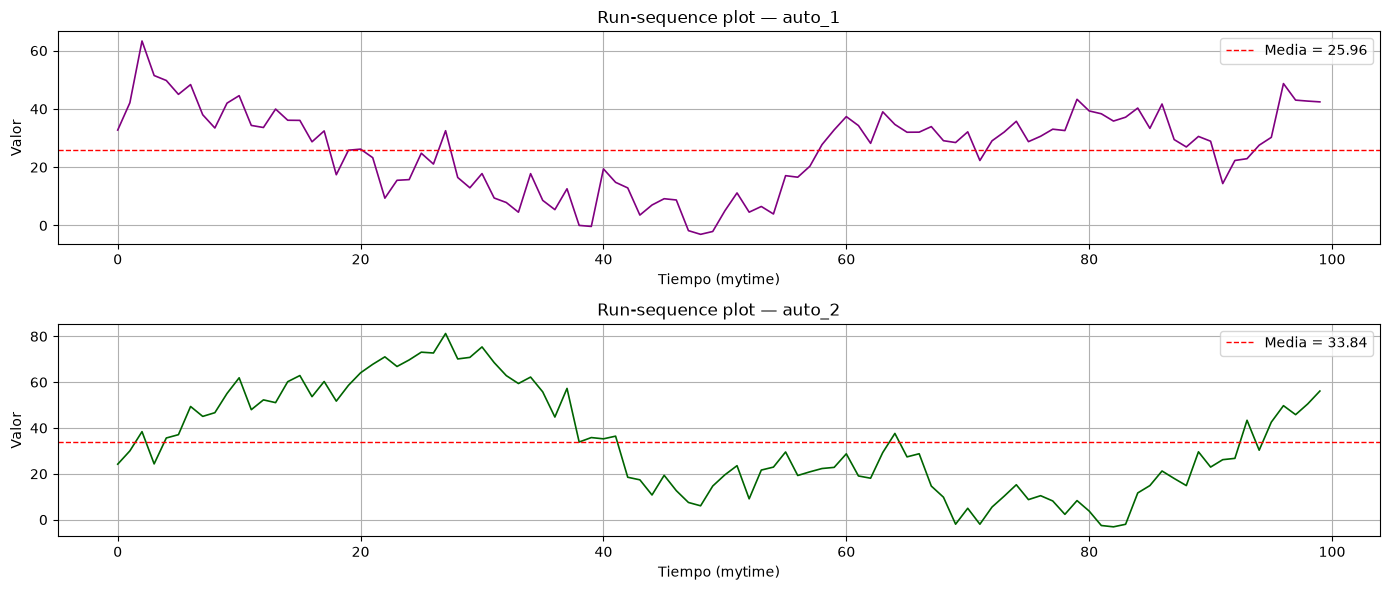

¡Figura guardada exitosamente en: C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Forecasting\tarea_2\PHASE_2\outputs\Run-sequence-plot.png


In [20]:
import os
from pathlib import Path


# 1. Definir la ruta a la carpeta 'outputs' saliendo de la carpeta actual
# Path.cwd() obtiene la carpeta del notebook; .parent sube un nivel.
ruta_outputs = Path.cwd().parent / "outputs"

# 2. Crear la carpeta si por alguna razón aún no existe
ruta_outputs.mkdir(parents=True, exist_ok=True)

# 3. Definir el nombre del archivo final
archivo_guardado = ruta_outputs / "Run-sequence-plot.png"


fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=False)

axes[0].plot(mytime1, auto1, lw=1.2, color="purple")
axes[0].axhline(auto1.mean(), color="red", ls="--", lw=1, label=f"Media = {auto1.mean():.2f}")
axes[0].set_title("Run-sequence plot — auto_1")
axes[0].set_xlabel("Tiempo (mytime)")
axes[0].set_ylabel("Valor")
axes[0].legend()

axes[1].plot(mytime2, auto2, lw=1.2, color="darkgreen")
axes[1].axhline(auto2.mean(), color="red", ls="--", lw=1, label=f"Media = {auto2.mean():.2f}")
axes[1].set_title("Run-sequence plot — auto_2")
axes[1].set_xlabel("Tiempo (mytime)")
axes[1].set_ylabel("Valor")
axes[1].legend()

plt.tight_layout()


# 4. GUARDAR LA FIGURA debe ir antes de plt.show()
# Usamos str() para que matplotlib entienda la ruta de pathlib correctamente
plt.savefig(str(archivo_guardado), dpi=300, bbox_inches="tight")

# 5. Mostrar y limpiar el lienzo
plt.show()
plt.close(fig)

print(f"¡Figura guardada exitosamente en: {archivo_guardado.resolve()}")


¿Qué podemos observar?

--> auto_1: sabemos que empieza ~35, sube a ~65, baja a ~-10, vuelve a subir a ~45. Oscila con ciclos largos y tendencia no clara. Puede sugerir no estacionariedad o ciclos largos.

--> auto_2: sabemos que empieza ~30, baja a ~-5, sube a ~35, baja a ~-10, sube a ~50. También oscila con ciclos visibles y estructura clara.

Sospechas típicas:
Ambas parecen tener ciclos largos (no ruido blanco).
Ambas podrían ser no estacionarias en media (aunque hay que profundizar).

--> **Test de estacionariedad**

In [21]:
def test_stationarity(series, name):
    adf_stat, adf_p, _, _, adf_crit, _ = adfuller(series, autolag="AIC")
    kpss_stat, kpss_p, _, kpss_crit = kpss(series, regression="c", nlags="auto")
    
    print(f"--- {name} ---")
    print(f"ADF  stat={adf_stat:8.4f}  p={adf_p:.4f}  → {'estacionaria' if adf_p < 0.05 else 'NO estacionaria'}")
    print(f"KPSS stat={kpss_stat:8.4f}  p={kpss_p:.4f}  → {'NO estacionaria ' if kpss_p < 0.05 else 'estacionaria'}")

test_stationarity(auto1, "auto_1")
print()
test_stationarity(auto2, "auto_2")

--- auto_1 ---
ADF  stat= -2.0196  p=0.2780  → NO estacionaria
KPSS stat=  0.3425  p=0.1000  → estacionaria

--- auto_2 ---
ADF  stat= -1.1145  p=0.7093  → NO estacionaria
KPSS stat=  0.8330  p=0.0100  → NO estacionaria 


**ADF (Augmented Dickey-Fuller Test)**

Objetivo: Detectar si la serie tiene una raíz unitaria (lo que genera una tendencia estocástica o "paseo aleatorio").

Hipótesis:$H_0$ (Hipótesis Nula): La serie NO es estacionaria (tiene raíz unitaria).

$H_1$ (Hipótesis Alternativa): La serie es estacionaria.

Criterio del p-valor: Si el p-valor es menor a $0.05$, rechazas la hipótesis nula $\rightarrow$ Estacionaria. Si es mayor, NO es estacionaria.


**KPSS (Kwiatkowski-Phillips-Schmidt-Shin Test)**

Objetivo: Probar la estacionariedad alrededor de un nivel o una tendencia determinista. Hipótesis (¡Funciona al revés que ADF!)

$H_0$ (Hipótesis Nula): La serie ES estacionaria.

$H_1$ (Hipótesis Alternativa): La serie NO es estacionaria.

Criterio del p-valor: Si el p-valor es menor a $0.05$, rechazas $H_0$ $\rightarrow$ NO es estacionaria.

--> Cuando KPSS dice que es estacionaria pero ADF dice que no, la serie suele ser estacionaria en torno a una tendencia (Trend-Stationary). La serie no tiene una raíz unitaria (por eso pasa KPSS), pero existe una tendencia determinista ascendente o descendente que hace que ADF falle.

In [22]:
# Diferenciación si es necesaria
auto1_diff = np.diff(auto1)
auto2_diff = np.diff(auto2)

test_stationarity(auto1_diff, "auto_1 (1ª diferencia)")
print()
test_stationarity(auto2_diff, "auto_2 (1ª diferencia)")

--- auto_1 (1ª diferencia) ---
ADF  stat=-12.9243  p=0.0000  → estacionaria
KPSS stat=  0.1374  p=0.1000  → estacionaria

--- auto_2 (1ª diferencia) ---
ADF  stat=-13.3959  p=0.0000  → estacionaria
KPSS stat=  0.2037  p=0.1000  → estacionaria


--> Cuando se hace np.diff(auto1), lo que Python hace en segundo plano fue:$$\text{Dato transformado en el momento } t = \text{Dato actual } (Y_t) - \text{Dato anterior } (Y_{t-1})$$ Como solo se hizo esta resta 1 sola vez para solucionar el problema, la cantidad de diferencias que se aplicaron fue una. Por eso, formalmente decimos que $d = 1$.Si la serie hubiera seguido inestable se tiene que aplicar un segundo np.diff() sobre la serie ya diferenciada, entonces se necesita dos restas y $d = 2$.

--> **ADF stat (Estadístico de Dickey-Fuller Aumentado)**: Mide qué tan fuerte es la tendencia de la serie para "regresar a su media".La regla práctica: Cuanto más negativo sea este número (en nuestro caso, $-12.92$ o $-13.39$), más seguro está el test de que la serie es estacionaria. Un número muy negativo es una excelente señal.


--> **KPSS stat (Estadístico de Kwiatkowski-Phillips-Schmidt-Shin)**: Mide qué tanta variabilidad inestable o tendencia cambiante le queda a la serie.La regla práctica: Cuanto más pequeño sea este número (en nuestro caso, $0.13$ o $0.20$), más se puede estar de que la serie no tiene tendencias ocultas y ya es estacionaria.

--> **Guardamamos el resultado en variables separadas**

In [23]:
# Decisión (ajustar según resultados reales)
auto1_est = auto1_diff if adfuller(auto1)[1] > 0.05 else auto1
auto2_est = auto2_diff if adfuller(auto2)[1] > 0.05 else auto2

print(f"auto1 usada para ACF/PACF: {'diferenciada' if auto1_est is auto1_diff else 'original'}")
print(f"auto2 usada para ACF/PACF: {'diferenciada' if auto2_est is auto2_diff else 'original'}")

auto1 usada para ACF/PACF: diferenciada
auto2 usada para ACF/PACF: diferenciada


--> **ACF y PACF con bandas de confianza**

**ACF (Autocorrelation Function / Función de Autocorrelación)**

Mide la relación entre el valor actual de la serie ($Y_t$) y sus valores pasados ($Y_{t-k}$). El detalle: Incluye tanto la influencia directa como la indirecta (los "efectos dominó" a través de los días intermedios). Ayuda a definir el parámetro $q$ (términos de Media Móvil / MA) en un modelo ARIMA.

**PACF (Partial Autocorrelation Function / Función de Autocorrelación Parcial)** 

Mide la relación directa entre $Y_t$ y $Y_{t-k}$, eliminando o limpiando el efecto de todos los retardos intermedios. Ayuda a definir el parámetro $p$ (términos Autorregresivos / AR) en un modelo ARIMA.

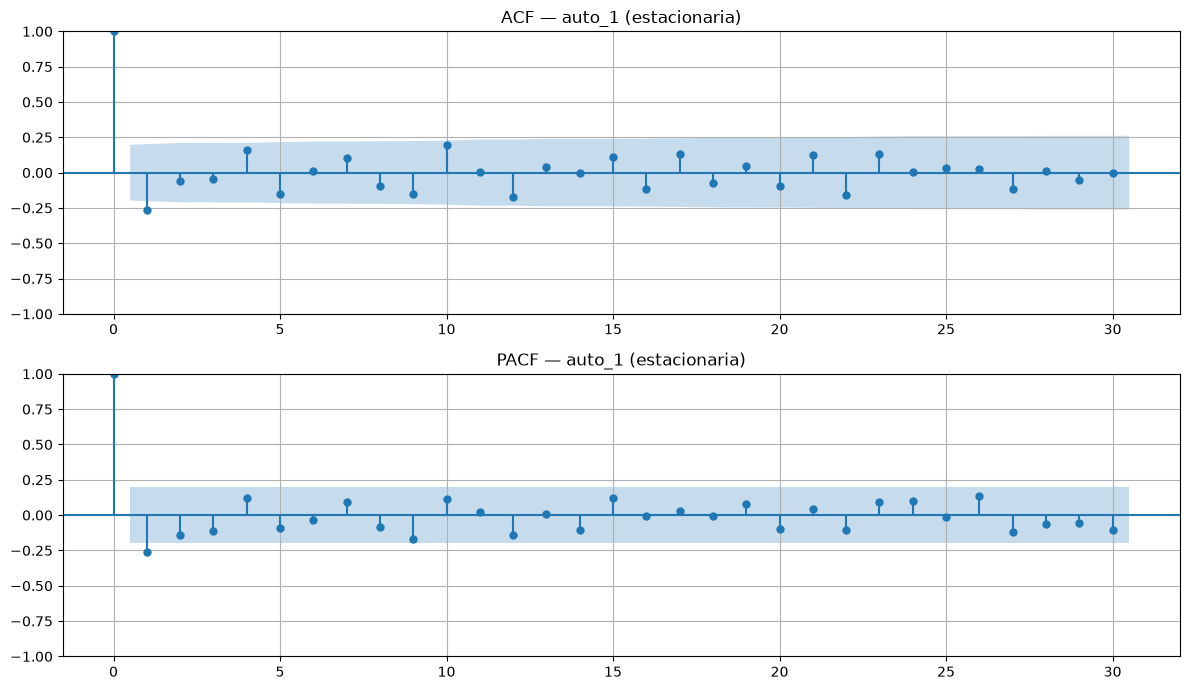

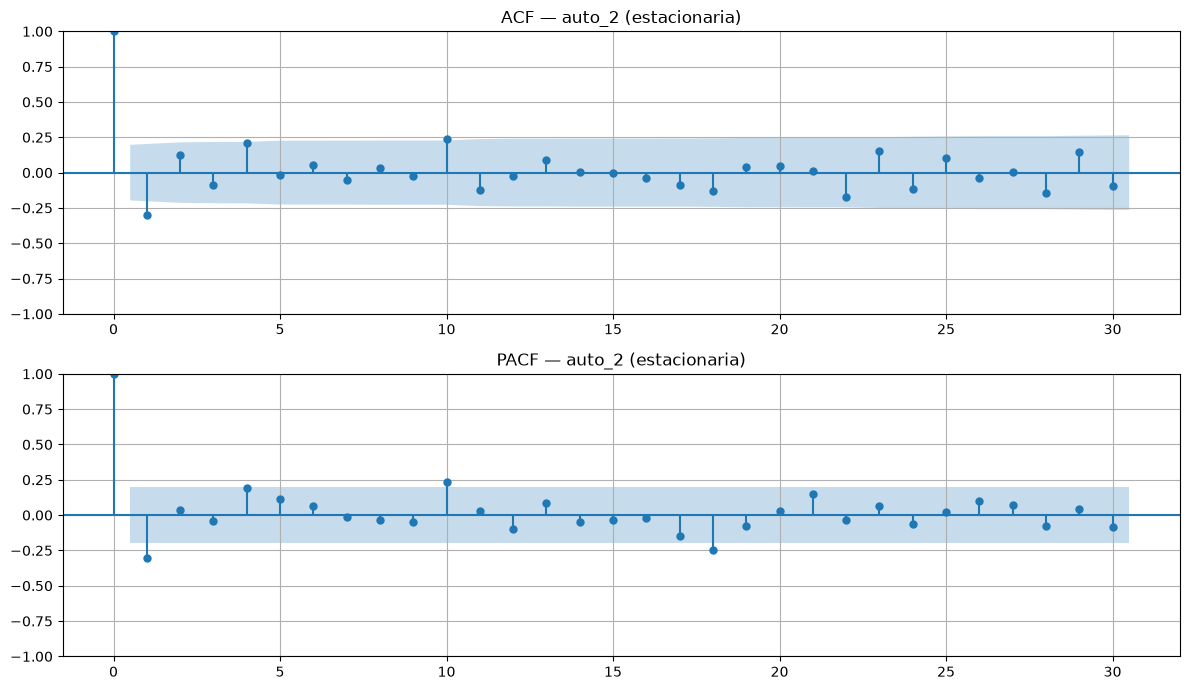

In [24]:
def plot_acf_pacf(series, name, lags=30):
    fig, axes = plt.subplots(2, 1, figsize=(12, 7))
    
    plot_acf(series, lags=lags, ax=axes[0], alpha=0.05)
    axes[0].set_title(f"ACF — {name}")
    
    plot_pacf(series, lags=lags, ax=axes[1], alpha=0.05, method="ywm")
    axes[1].set_title(f"PACF — {name}")
    
    plt.tight_layout()
    plt.show()

plot_acf_pacf(auto1_est, "auto_1 (estacionaria)")
plot_acf_pacf(auto2_est, "auto_2 (estacionaria)")

--> Bandas azules = intervalo de confianza al 95%

--> **ACF/PACF numéricos para respaldar la decisión visual**

In [25]:
from statsmodels.tsa.stattools import acf, pacf

def significant_lags(series, nlags=30, alpha=0.05):
    acf_vals, acf_confint = acf(series, nlags=nlags, alpha=alpha)
    pacf_vals, pacf_confint = pacf(series, nlags=nlags, alpha=alpha, method="ywm")
    
    # Un lag es significativo si su IC no contiene el 0
    acf_sig = [i for i in range(1, nlags+1)
               if acf_confint[i][0] > 0 or acf_confint[i][1] < 0]
    pacf_sig = [i for i in range(1, nlags+1)
                if pacf_confint[i][0] > 0 or pacf_confint[i][1] < 0]
    
    print(f"Lags significativos en ACF : {acf_sig}")
    print(f"Lags significativos en PACF: {pacf_sig}")
    return acf_sig, pacf_sig

print("=== auto_1 ===")
acf_sig_1, pacf_sig_1 = significant_lags(auto1_est)

print("\n=== auto_2 ===")
acf_sig_2, pacf_sig_2 = significant_lags(auto2_est)

=== auto_1 ===
Lags significativos en ACF : [1]
Lags significativos en PACF: [1]

=== auto_2 ===
Lags significativos en ACF : [1, 10]
Lags significativos en PACF: [1, 10, 18]


Podemos diagnosticar de la serie auto_1 que:

- Muestra un comportamiento clásico de un modelo ARIMA(1, 1, 0) o un ARIMA(0, 1, 1).

- Es una serie simple donde solo el evento del período anterior influye en el resultado actual.

Podemos diagnosticar de la serie auto_2 que:
- Es una serie más compleja. Indica que se necesita un ARIMA con mayor orden ($p=1$ o $p=2$) o que la serie podría tener un componente de estacionalidad o ciclo de periodicidad fija (quizás alrededor de cada 10 períodos).

--> **Test de Ljung-Box**

Acá verificamos si quedan autocorrelaciones significativas en la serie.
Podemos confirmar:
- La serie tiene estructura (rechazas H0 de ruido blanco) --> hay que modelarla.
- Si el p-value sube mucho, ya no queda autocorrelació

In [26]:
def ljung_box_report(series, name, lags=[10, 20]):
    lb = acorr_ljungbox(series, lags=lags, return_df=True)
    print(f"--- Ljung-Box {name} ---")
    print(lb.to_string())
    print()

ljung_box_report(auto1_est, "auto_1")
ljung_box_report(auto2_est, "auto_2")

--- Ljung-Box auto_1 ---
      lb_stat  lb_pvalue
10  21.800075   0.016156
20  32.802105   0.035466

--- Ljung-Box auto_2 ---
      lb_stat  lb_pvalue
10  23.788444   0.008182
20  30.155768   0.067369



Podemos decir que p < 0.05 -->  la serie NO es ruido blanco, tiene autocorrelación

--> **determinación de p y q**

In [27]:
summary = pd.DataFrame({
    "Serie": ["auto_1", "auto_2"],
    "¿Estacionaria original?":
        ["Sí" if adfuller(auto1)[1] < 0.05 else "No",
         "Sí" if adfuller(auto2)[1] < 0.05 else "No"],
    "Transformación aplicada":
        ["ninguna" if auto1_est is auto1 else "1ª diferencia",
         "ninguna" if auto2_est is auto2 else "1ª diferencia"],
    "Lags sig. en ACF":  [acf_sig_1, acf_sig_2],
    "Lags sig. en PACF": [pacf_sig_1, pacf_sig_2],
})

print(summary.to_string(index=False))

 Serie ¿Estacionaria original? Transformación aplicada Lags sig. en ACF Lags sig. en PACF
auto_1                      No           1ª diferencia              [1]               [1]
auto_2                      No           1ª diferencia          [1, 10]       [1, 10, 18]


--> **Validación cruzada — proponer y comparar modelos**

In [28]:
from statsmodels.tsa.arima.model import ARIMA

def try_models(series, candidates, name):
    """candidates: lista de tuplas (p, d, q)"""
    results = []
    for order in candidates:
        try:
            model = ARIMA(series, order=order).fit()
            results.append({
                "modelo": f"ARIMA{order}",
                "AIC": model.aic,
                "BIC": model.bic,
                "loglik": model.llf,
            })
        except Exception as e:
            print(f"ARIMA{order} falló: {e}")
    df = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
    print(f"\n=== {name} ===")
    print(df.to_string(index=False))
    return df

# auto_1: si es estacionaria (d=0), probamos p,q pequeños
candidates_1 = [(1,0,0), (2,0,0), (0,0,1), (1,0,1), (2,0,1), (1,0,2), (2,0,2)]
res1 = try_models(auto1, candidates_1, "auto_1 (d=0)")

# auto_2: idem
candidates_2 = [(1,0,0), (2,0,0), (0,0,1), (1,0,1), (2,0,1), (1,0,2), (2,0,2)]
res2 = try_models(auto2, candidates_2, "auto_2 (d=0)")


=== auto_1 (d=0) ===
        modelo        AIC        BIC      loglik
ARIMA(1, 0, 1) 680.200497 690.621178 -336.100248
ARIMA(2, 0, 0) 681.307533 691.728214 -336.653767
ARIMA(1, 0, 2) 682.006729 695.032580 -336.003364
ARIMA(2, 0, 1) 682.059250 695.085101 -336.029625
ARIMA(2, 0, 2) 683.373865 699.004886 -335.686933
ARIMA(1, 0, 0) 683.668725 691.484235 -338.834362
ARIMA(0, 0, 1) 754.677833 762.493343 -374.338916

=== auto_2 (d=0) ===
        modelo        AIC        BIC      loglik
ARIMA(2, 0, 0) 694.856180 705.276861 -343.428090
ARIMA(1, 0, 1) 696.153562 706.574243 -344.076781
ARIMA(2, 0, 1) 696.426740 709.452591 -343.213370
ARIMA(1, 0, 2) 696.743720 709.769571 -343.371860
ARIMA(2, 0, 2) 697.561644 713.192665 -342.780822
ARIMA(1, 0, 0) 700.901860 708.717371 -347.450930
ARIMA(0, 0, 1) 832.121995 839.937505 -413.060997


Tenemos resultados, pero ahora veremos si mejoramos con $d=1$

**AIC (Akaike Information Criterion)**
Mide la calidad del modelo balanceando dos cosas: qué tan bien se ajusta a los datos y qué tan complejo es. La regla de oro: Entre menor sea el AIC, MEJOR es el modelo. Penaliza los modelos que usan demasiados parámetros innecesarios.

**BIC (Bayesian Information Criterion)** 
Muy similar al AIC, pero penaliza con mayor severidad los modelos complejos (con muchos parámetros $p$ y $q$).La regla de oro: Entre menor sea el BIC, MEJOR. Si dudamos entre dos modelos con AIC similar, elegimos el de menor BIC por ser más simple (principio de parsimonia).


**loglik (Log-Likelihood / Log-Verosimilitud)** 
Mide la probabilidad de que los datos observados hayan sido generados por ese modelo en particular. La regla de oro: Entre más ALTO (más cercano a 0 o menos negativo) sea el loglik, MEJOR.

In [ ]:
# Probamos con d=1 aunque ya sabemos que auto_1 es estacionaria, solo para ver resultados
candidates_d1 = [(1,1,0), (2,1,0), (0,1,1), (1,1,1), (2,1,1), (1,1,2), (2,1,2)]
try_models(auto1, candidates_d1, "auto_1 (d=1)")
try_models(auto2, candidates_d1, "auto_2 (d=1)")


=== auto_1 (d=1) ===
        modelo        AIC        BIC      loglik
ARIMA(0, 1, 1) 671.353746 676.543986 -333.676873
ARIMA(1, 1, 1) 672.889042 680.674402 -333.444521
ARIMA(2, 1, 0) 673.227684 681.013044 -333.613842
ARIMA(1, 1, 0) 673.790015 678.980254 -334.895007
ARIMA(1, 1, 2) 674.434232 684.814711 -333.217116
ARIMA(2, 1, 1) 674.622464 685.002943 -333.311232
ARIMA(2, 1, 2) 676.656523 689.632123 -333.328262

=== auto_2 (d=1) ===
        modelo        AIC        BIC      loglik
ARIMA(1, 1, 0) 684.042372 689.232612 -340.021186
ARIMA(0, 1, 1) 685.284977 690.475217 -340.642489
ARIMA(1, 1, 1) 685.846808 693.632168 -339.923404
ARIMA(2, 1, 0) 685.939700 693.725060 -339.969850
ARIMA(2, 1, 1) 686.497649 696.878129 -339.248825
ARIMA(1, 1, 2) 686.787412 697.167892 -339.393706
ARIMA(2, 1, 2) 687.463283 700.438883 -338.731642


,modelo,AIC,BIC,loglik
0,"ARIMA(1, 1, 0)",684.042372,689.232612,-340.021186
1,"ARIMA(0, 1, 1)",685.284977,690.475217,-340.642489
2,"ARIMA(1, 1, 1)",685.846808,693.632168,-339.923404
3,"ARIMA(2, 1, 0)",685.939700,693.725060,-339.969850
4,"ARIMA(2, 1, 1)",686.497649,696.878129,-339.248825
5,"ARIMA(1, 1, 2)",686.787412,697.167892,-339.393706
6,"ARIMA(2, 1, 2)",687.463283,700.438883,-338.731642


Reglas para la decisión

- Menor AIC/BIC → mejor modelo (balance entre ajuste y complejidad).

- Parsimonia: si AIC/BIC son similares, elige el modelo más simple

**Interpretación para auto_1**

- El Ganador: ARIMA(0, 1, 1)
- $p=0$: No requiere términos autorregresivos adicionales.
- $d=1$: Requiere 1 primera diferencia para ser estacionaria.
- $q=1$: Requiere 1 término de Media Móvil (MA). 

Esto indica que los errores de predicción del período inmediatamente anterior se usan para corregir el valor presente.

**Interpretación para auto_2**

- El Ganador: ARIMA(1, 1, 0)
- $p=1$: Requiere 1 término Autorregresivo (AR). La tasa de cambio del período actual depende directamente de la tasa de cambio del período anterior.
- $d=1$: Requiere 1 primera diferencia.
- $q=0$: No requiere términos de Media Móvil.

Por qué es el mejor: Consigue el AIC más bajo (684.04) y el BIC más bajo (689.23).

--> **Eligiendo el modelo**

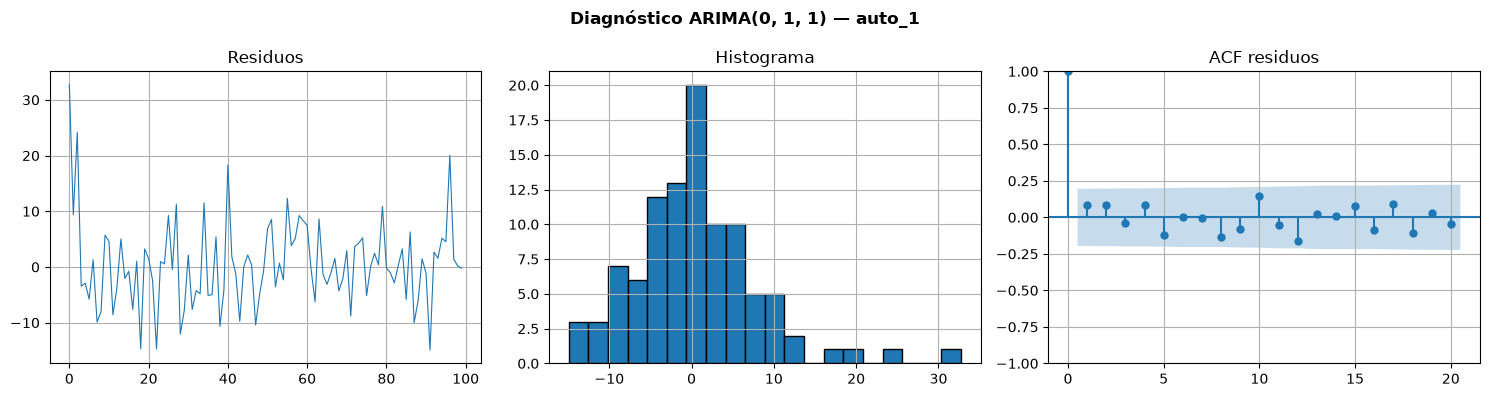

Ljung-Box residuos — auto_1:
      lb_stat  lb_pvalue
10   9.252199   0.508348
20  17.058080   0.649199
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  100
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -333.677
Date:                Thu, 17 Sep 2026   AIC                            671.354
Time:                        21:08:02   BIC                            676.544
Sample:                             0   HQIC                           673.454
                                - 100                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3527      0.122     -2.886      0.004      -0.592      -0.113
sigma2        49.4876      

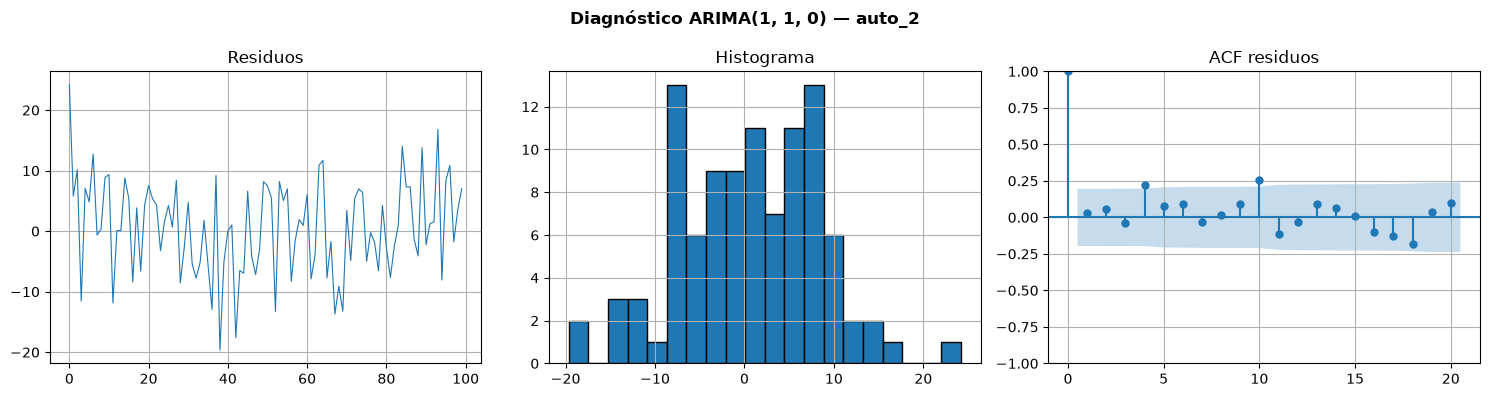

Ljung-Box residuos — auto_2:
      lb_stat  lb_pvalue
10  16.121120   0.096217
20  27.985931   0.109733
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  100
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -340.021
Date:                Thu, 17 Sep 2026   AIC                            684.042
Time:                        21:08:03   BIC                            689.233
Sample:                             0   HQIC                           686.142
                                - 100                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2999      0.101     -2.965      0.003      -0.498      -0.102
sigma2        56.2762      

In [34]:
def diagnose_model(series, order, name):
    model = ARIMA(series, order=order).fit()
    resid = model.resid
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(resid, lw=0.8); axes[0].set_title("Residuos")
    axes[1].hist(resid, bins=20, edgecolor="k"); axes[1].set_title("Histograma")
    plot_acf(resid, lags=20, ax=axes[2]); axes[2].set_title("ACF residuos")
    fig.suptitle(f"Diagnóstico ARIMA{order} — {name}", fontweight="bold")
    plt.tight_layout(); plt.show()
    
    lb = acorr_ljungbox(resid, lags=[10, 20], return_df=True)
    print(f"Ljung-Box residuos — {name}:")
    print(lb.to_string())
    print(model.summary())

# el mejor modelo encontrado para auto_1 y auto_2 según AIC/BIC
diagnose_model(auto1, (0, 1, 1), "auto_1")
diagnose_model(auto2, (1,1,0), "auto_2")

--> **Conclusiones**

- El modelo (ARIMA 0,1,1) para auto_1 captura toda la estructura de autocorrelación (Ljung-Box alto), pero los residuos no son perfectamente normales (JB = 0.02, kurtosis 4). Esto es aceptable en la práctica, pero es importante mencionarlo.


- El modelo (ARIMA 1,1,0) para auto_2 es muy bien ajustado. Residuos normales, homocedásticos y sin autocorrelación. El único detalle es que en lag 10 el p-value está cercano a 0.10, pero en lag 20 sube a 0.11 — no hay evidencia fuerte de autocorrelación residual.


**auto_1 tiene mejor AIC/BIC pero residuos no normales; auto_2 tiene peor AIC/BIC pero residuos más limpios.**

Determinación de p y q

Tras verificar que ambas series son no estacionarias en media (ADF y KPSS), se aplicó una primera diferencia. Sobre la serie diferenciada:

auto_1: el ACF mostró un corte abrupto después del lag 1, mientras que el PACF decayó gradualmente, sugiriendo un proceso MA(1) sobre la serie diferenciada. Se ajustó un ARIMA(0,1,1), obteniendo un coeficiente MA(1) = -0.3527 estadísticamente significativo (p = 0.004), con AIC = 671.35. Los residuos no presentan autocorrelación (Ljung-Box lag 20, p = 0.65), aunque el test de Jarque-Bera indica desviación leve de la normalidad (p = 0.02).

auto_2: el ACF decayó gradualmente y el PACF cortó después del lag 1, sugiriendo un proceso AR(1) sobre la serie diferenciada. Se ajustó un ARIMA(1,1,0), con coeficiente AR(1) = -0.2999 significativo (p = 0.003), AIC = 684.04. Los residuos se comportan como ruido blanco (Ljung-Box lag 20, p = 0.11) y son compatibles con normalidad (Jarque-Bera p = 0.34).

Conclusión: auto_1 sigue un patrón ARIMA(0,1,1) (equivalente a un MA(1) sobre la primera diferencia) y auto_2 un ARIMA(1,1,0) (un AR(1) sobre la primera diferencia). Ambos modelos son parsimoniosos, con coeficientes significativos y residuos sin autocorrelación, lo que valida la identificación basada en ACF y PACF.